<a href="https://colab.research.google.com/github/BeatrizYukihara/deteccao-de-buracos-visao-computacional/blob/main/notebooks/01_extracao_de_frames.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **Extração de frames de vídeo**

Converte os vídeos de percurso (trabalho = treino, faculdade = teste) em imagens.

Cada vídeo gera uma pasta em `frames/`. Vídeos já processados são pulados,
e frames quase idênticos (carro parado) são descartados.
Vídeos gravados em HDR são convertidos para SDR antes da extração,
senão os frames saem claros e sem contraste.

In [2]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [3]:
#configurações

import os, re, shutil, cv2

PASTA_BASE   = '/content/drive/MyDrive/deteccao-de-buracos-visao-computacional'
PASTA_VIDEOS = f'{PASTA_BASE}/brutos/videos'
PASTA_FRAMES = f'{PASTA_BASE}/frames'

FRAMES_POR_SEGUNDO = 1     # 1 frame por segundo de vídeo
LIMIAR_DIFERENCA   = 12    # maior = descarta mais frames parecidos
LARGURA_SAIDA      = 1280  # largura das imagens salvas, em pixels
EXTENSOES = ('.mp4', '.mov', '.avi')

# v001_2026-10-21_trabalho  ou  v005_2026-10-22_trabalho_p2
PADRAO_NOME = re.compile(r'^(v\d{3}_\d{4}-\d{2}-\d{2}_(?:trabalho|faculdade))(?:_p(\d+))?$')

os.makedirs(PASTA_VIDEOS, exist_ok=True)
os.makedirs(PASTA_FRAMES, exist_ok=True)

In [4]:
#função de extração

from tqdm.auto import tqdm

def extrair_frames(caminho_video, pasta_saida, id_video, inicio=0,
                   fps_alvo=FRAMES_POR_SEGUNDO, limiar=LIMIAR_DIFERENCA):
    cap = cv2.VideoCapture(caminho_video)
    if not cap.isOpened():
        raise RuntimeError(f'OpenCV não conseguiu abrir {caminho_video} (codec?)')

    fps = cap.get(cv2.CAP_PROP_FPS) or 30
    total_frames = int(cap.get(cv2.CAP_PROP_FRAME_COUNT)) or None
    passo = max(1, round(fps / fps_alvo))

    i = amostrados = 0
    salvos = inicio
    ultimo = None
    barra = tqdm(total=total_frames, desc=os.path.basename(caminho_video), unit='fr')
    while cap.grab():
        if i % passo == 0:
            ok, frame = cap.retrieve()
            if not ok:
                break
            amostrados += 1
            if LARGURA_SAIDA and frame.shape[1] > LARGURA_SAIDA:
                h = round(frame.shape[0] * LARGURA_SAIDA / frame.shape[1])
                frame = cv2.resize(frame, (LARGURA_SAIDA, h))
            pequeno = cv2.resize(cv2.cvtColor(frame, cv2.COLOR_BGR2GRAY), (160, 90))
            if ultimo is None or cv2.absdiff(pequeno, ultimo).mean() > limiar:
                cv2.imwrite(f'{pasta_saida}/{id_video}_{salvos:05d}.jpg', frame)
                ultimo = pequeno
                salvos += 1
        i += 1
        barra.update(1)
    barra.close()
    cap.release()
    return amostrados, salvos - inicio

In [5]:
#função de conversão HDR -> SDR, para alguns video gravados com essa opção por acidente

import subprocess, json

def detectar_hdr(caminho):
    saida = subprocess.run(['ffprobe', '-v', 'error', '-select_streams', 'v:0',
                            '-show_entries', 'stream=color_transfer', '-of', 'json', caminho],
                           capture_output=True, text=True).stdout
    transf = json.loads(saida)['streams'][0].get('color_transfer', '')
    return transf in ('arib-std-b67', 'smpte2084'), transf   # HLG (iPhone) ou PQ

def converter_para_sdr(caminho, transf):
    saida = os.path.splitext(caminho)[0] + '_sdr.mp4'
    filtro = (f'fps={FRAMES_POR_SEGUNDO},scale={LARGURA_SAIDA}:-2,'
              f'zscale=tin={transf}:t=linear:npl=100,format=gbrpf32le,'
              'zscale=p=bt709,tonemap=tonemap=hable:desat=0,'
              'zscale=t=bt709:m=bt709:r=tv,format=yuv420p')
    subprocess.run(['ffmpeg', '-y', '-v', 'error', '-stats', '-i', caminho, '-vf', filtro,
                    '-c:v', 'libx264', '-crf', '18', '-preset', 'veryfast', '-an', saida],
                   check=True)
    return saida

In [6]:
#processar os vídeos novos

from collections import defaultdict

LOCAL = '/content/trabalho_local'

grupos = defaultdict(list)
for arquivo in os.listdir(PASTA_VIDEOS):
    if not arquivo.lower().endswith(EXTENSOES):
        continue
    m = PADRAO_NOME.match(os.path.splitext(arquivo)[0])
    if not m:
        print(f'⚠ {arquivo}: nome fora do padrão, pulando')
        continue
    grupos[m.group(1)].append((int(m.group(2) or 1), arquivo))

print(f'{len(grupos)} vídeo(s) encontrados', flush=True)

for base in sorted(grupos):
    pasta_saida = f'{PASTA_FRAMES}/{base}'
    if os.path.exists(pasta_saida):
        print(f'{base}: já processado')
        continue

    shutil.rmtree(LOCAL, ignore_errors=True)
    os.makedirs(f'{LOCAL}/frames')

    id_video = base.split('_')[0]
    total = 0
    for parte, arquivo in sorted(grupos[base]):
        print(f'copiando {arquivo} para o disco local...', flush=True)
        local_video = shutil.copy(f'{PASTA_VIDEOS}/{arquivo}', LOCAL)
        hdr, transf = detectar_hdr(local_video)
        if hdr:
            print(f'  {arquivo} é HDR ({transf}), convertendo para SDR...', flush=True)
            sdr = converter_para_sdr(local_video, transf)
            os.remove(local_video)
            local_video = sdr
        _, salvos = extrair_frames(local_video, f'{LOCAL}/frames', id_video, inicio=total)
        os.remove(local_video)
        total += salvos
        print(f'  {arquivo}: {salvos} frames', flush=True)

    if total == 0:
        print(f'⚠ {base}: nenhum frame extraído, não vou marcar como processado')
        continue

    print(f'copiando {total} frames para o Drive...', flush=True)
    shutil.copytree(f'{LOCAL}/frames', pasta_saida + '_tmp', dirs_exist_ok=True)
    os.rename(pasta_saida + '_tmp', pasta_saida)
    print(f'{base}: {total} frames no total')

9 vídeo(s) encontrados
v001_2026-10-21_trabalho: já processado
v002_2026-10-22_trabalho: já processado
v003_2026-10-22_trabalho: já processado
copiando v004_2026-10-22_faculdade.MOV para o disco local...


v004_2026-10-22_faculdade.MOV:   0%|          | 0/18112 [00:00<?, ?fr/s]

  v004_2026-10-22_faculdade.MOV: 557 frames
copiando 557 frames para o Drive...
v004_2026-10-22_faculdade: 557 frames no total
copiando v005_2026-10-22_faculdade.MOV para o disco local...


v005_2026-10-22_faculdade.MOV:   0%|          | 0/16210 [00:00<?, ?fr/s]

  v005_2026-10-22_faculdade.MOV: 515 frames
copiando 515 frames para o Drive...
v005_2026-10-22_faculdade: 515 frames no total
copiando v006_2026-10-23_trabalho_p1.MOV para o disco local...


...

  v007_2026-10-23_trabalho.MOV: 1541 frames
copiando 1541 frames para o Drive...
v007_2026-10-23_trabalho: 1541 frames no total
copiando v008_2026-10-23_faculdade.MOV para o disco local...


v008_2026-10-23_faculdade.MOV:   0%|          | 0/18731 [00:00<?, ?fr/s]

  v008_2026-10-23_faculdade.MOV: 581 frames
copiando 581 frames para o Drive...
v008_2026-10-23_faculdade: 581 frames no total
copiando v009_2026-10-23_faculdade.MOV para o disco local...


v009_2026-10-23_faculdade.MOV:   0%|          | 0/17948 [00:00<?, ?fr/s]

  v009_2026-10-23_faculdade.MOV: 517 frames
copiando 517 frames para o Drive...
v009_2026-10-23_faculdade: 517 frames no total


In [7]:
#resumo do banco

import pandas as pd

linhas = []
for pasta in sorted(os.listdir(PASTA_FRAMES)):
    if pasta.endswith('_tmp'):
        continue
    linhas.append({
        'video': pasta,
        'origem': pasta.split('_')[-1],
        'frames': len(os.listdir(f'{PASTA_FRAMES}/{pasta}')),
    })

resumo = pd.DataFrame(linhas)
display(resumo)
display(resumo.groupby('origem')['frames'].sum())

,video,origem,frames
0,v001_2026-10-21_trabalho,trabalho,1397
1,v002_2026-10-22_trabalho,trabalho,1490
2,v003_2026-10-22_trabalho,trabalho,1113
3,v004_2026-10-22_faculdade,faculdade,557
4,v005_2026-10-22_faculdade,faculdade,515
5,v006_2026-10-23_trabalho,trabalho,1355
6,v007_2026-10-23_trabalho,trabalho,1541
7,v008_2026-10-23_faculdade,faculdade,581
8,v009_2026-10-23_faculdade,faculdade,517


,frames
origem,
faculdade,2170
trabalho,6896


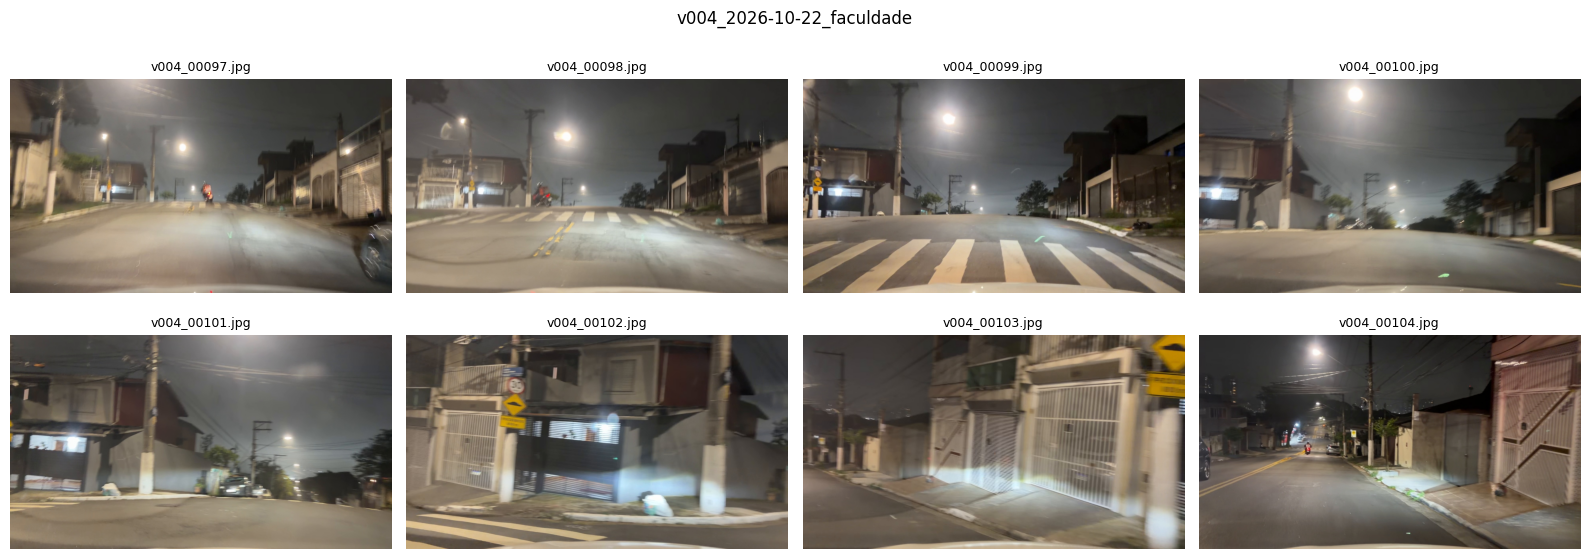

In [9]:
#conferir frames em sequência

import matplotlib.pyplot as plt
import random

pastas = [p for p in os.listdir(PASTA_FRAMES) if not p.endswith('_tmp')]
pasta = random.choice(pastas)
arquivos = sorted(os.listdir(f'{PASTA_FRAMES}/{pasta}'))
inicio = random.randint(0, max(0, len(arquivos) - 8))

fig, eixos = plt.subplots(2, 4, figsize=(16, 6))
for ax in eixos.flat:
    ax.axis('off')
for ax, f in zip(eixos.flat, arquivos[inicio:inicio + 8]):
    img = cv2.cvtColor(cv2.imread(f'{PASTA_FRAMES}/{pasta}/{f}'), cv2.COLOR_BGR2RGB)
    ax.imshow(img)
    ax.set_title(f, fontsize=9)
plt.suptitle(pasta)
plt.tight_layout()
plt.show()